# MLOps: Observability Hands-On (Logs, Metrics, Traces, SLOs and Drift)

> **Who is this for:** anyone who will run an ML or LLM service in production and needs to answer, at 3 a.m., "is it broken, for whom, since when, and why?". It is also for students who want the SRE vocabulary (SLI, SLO, error budget, burn rate, RED/USE) that comes up in MLOps and system-design interviews.
>
> **What you will learn:**
> - The **three pillars** (logs, metrics, traces) plus **profiles**; the **RED** and **USE** methods; what to record for ML and LLM services (input hash, model version, latency, tokens, cost)
> - **Structured JSON logging** with **request IDs** that follow a request through a FastAPI app
> - **Metrics with `prometheus_client`**: counters, gauges, histograms; computing **p50/p95/p99 from buckets** (like PromQL's `histogram_quantile`); exposing and parsing `/metrics`
> - **Tracing with the OpenTelemetry SDK** (in-memory exporter): spans for retrieval → rerank → generation in a fake RAG pipeline, context propagation with `traceparent`, and **finding the slow span**
> - **SLIs, SLOs and error budgets**; **multi-window, multi-burn-rate alerts** evaluated on 30 days of synthetic traffic and compared with a naive threshold
> - **ML-specific monitors**: data drift (**PSI, KS, MMD**), prediction drift, **delayed labels**, and choosing alert thresholds from a **false-alarm-rate** analysis
> - A **Grafana dashboard as JSON**, rendered with matplotlib
> - An **incident drill**: a deploy plus an input-distribution shift, detected, diagnosed, mitigated and written up
>
> **Prerequisites:** [`06_monitoring/01`](06_monitoring/01_monitoring.ipynb) (drift concepts), [FastAPI intro](../12_FastAPI/01_fastapi_intro.ipynb), and ideally [`23_Software_Engineering/09` system design](../23_Software_Engineering/09_system_design_fundamentals.ipynb) (§7 introduces SLOs).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet, no Prometheus/Grafana/Jaeger servers: everything runs in-process (FastAPI `TestClient`, an in-memory span exporter, synthetic metric streams). About 1 minute.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

### How this notebook is different from the other monitoring material

| Existing notebook | This notebook |
|---|---|
| [`06_monitoring/01_monitoring`](06_monitoring/01_monitoring.ipynb) explains drift types and tests, and shows Evidently / Prometheus / Grafana configuration as text (3 code cells) | **Runs** every pillar: JSON logs, a real `/metrics` endpoint, OpenTelemetry spans, and computes quantiles, burn rates and drift statistics from scratch |
| [`15_industry_end_to_end_mlops_pipeline`](15_industry_end_to_end_mlops_pipeline.ipynb) uses drift as a **retraining trigger** in a batch pipeline | Focuses on **online services**: latency, errors, SLOs and alert quality, plus drift with **false-alarm control** |
| [`13_llmops`](13_llmops.ipynb) lists LLM monitoring concerns (cost, latency SLAs, hallucination) | Implements **traces of an LLM/RAG request** and token/cost attributes with OpenTelemetry |
| [`23_Software_Engineering/11`](../23_Software_Engineering/11_industry_building_and_shipping_an_ai_feature.ipynb) §7 adds basic logging and metrics to one feature | Goes deep on **alerting** (burn rates), **dashboards** and an **incident drill** |

## Explained simply

Once a model is running for real users, you cannot watch it with your own eyes. **Observability** means the system writes down enough about itself that you can tell, from the outside, whether it is healthy and why it is not. It writes three kinds of notes: **logs** (a diary entry for each event: "request 42 took 0.3 s with model v2"), **metrics** (counters and gauges, like a car's dashboard: speed, fuel, engine temperature) and **traces** (a timeline of one request as it passes through every step, like a parcel-tracking page). On top of these we set **promises** (an SLO such as "99.5% of requests succeed") and alarms that ring only when the promise is really in danger, so engineers are not woken up for nothing. ML adds a twist: a model can be "up" and fast but quietly giving worse answers because the world changed, so we also watch the **data** for drift.

**Everyday analogies.**
- A **trace** is like a parcel-tracking page: "picked up 09:00 → sorting centre 11:30 → out for delivery 15:00". If the parcel is late, you see exactly which leg was slow.
- An **error budget** is like a monthly mobile-data allowance: a little waste is fine, but if you burn through it in a week, you must slow down (stop risky releases) until the month resets.
- **Data drift** is like a shop's customers changing: a winter-coat shop's sales model trained in December will be confused in July, even though nothing in the shop is broken.

**A tiny example.** A service promises that 99.5% of requests succeed over 30 days. With 1,000,000 requests a month, that allows 0.5% × 1,000,000 = **5,000 failed requests** (the error budget). If one bad deploy fails 2,000 requests in an hour, it has spent 40% of the month's budget in that hour, which is an emergency. Fifty random failures spread over a day are only 1%: no need to wake anyone.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Logs, metrics, traces | diary, dashboard, parcel tracking | debugging why one chatbot answer took 9 seconds |
| SLO and error budget | a reliability promise and the failures it allows | "99.9% of API calls succeed" for an LLM API |
| Drift monitor | an alarm when incoming data no longer looks like training data | a fraud model whose inputs change after a new app release |

## 0. Setup

> 💬 **In plain English:** load the libraries, a tiny model to serve, and helpers; nothing talks to the internet.

In [1]:
import contextvars, hashlib, io, json, logging, math, random, shutil, sys, tempfile, time, uuid, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

import prometheus_client
from prometheus_client import CollectorRegistry, Counter, Gauge, Histogram, generate_latest, CONTENT_TYPE_LATEST
from prometheus_client.parser import text_string_to_metric_families
from opentelemetry import trace
from opentelemetry.sdk.resources import Resource
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import SimpleSpanProcessor
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter
from opentelemetry.trace.propagation.tracecontext import TraceContextTextMapPropagator
from fastapi import FastAPI, Response
from fastapi.responses import JSONResponse
from fastapi.testclient import TestClient
from pydantic import BaseModel

prometheus_client.disable_created_metrics()          # hide the *_created series to keep the output short
random.seed(0); np.random.seed(0)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)

WORK = Path(tempfile.mkdtemp(prefix="obs16_"))       # files we write (dashboard JSON) go here

# The model we will serve: a small classifier on 4 synthetic features
X_train, y_train = make_classification(n_samples=4000, n_features=4, n_informative=3, n_redundant=0, random_state=0)
MODEL = LogisticRegression().fit(X_train, y_train)
print("Python", sys.version.split()[0], "| model to serve trained, train accuracy", round(MODEL.score(X_train, y_train), 3))

Python 3.12.3 | model to serve trained, train accuracy 0.734


## 1. What to observe: three pillars, RED, USE and the ML extras

> 💬 **In plain English:** decide what to record before writing any code: three pillars, two checklists, and an ML-specific list.

**Definitions.**
- **Monitoring** answers known questions ("is the error rate above 1%?"). **Observability** is the property of a system that lets you answer *new* questions from its outputs without shipping new code.
- **Logs:** timestamped, structured records of discrete events. High detail, high volume, expensive to keep.
- **Metrics:** numeric time series, pre-aggregated (counters, gauges, histograms). Cheap, fast to query, ideal for dashboards and alerts, but low detail.
- **Traces:** the path of one request through the system as a tree of timed **spans**. They show *where* the time went.
- **Profiles:** where CPU time and memory go inside a process (continuous profiling, the "fourth pillar"; see [`23_Software_Engineering/04`](../23_Software_Engineering/04_debugging_and_profiling.ipynb)).

**Two checklists:**

| Method | For | Signals |
|---|---|---|
| **RED** (Tom Wilkie) | request-driven services (APIs, model servers) | **R**ate (requests/s), **E**rrors (failed requests/s), **D**uration (latency distribution) |
| **USE** (Brendan Gregg) | resources (CPU, GPU, memory, disks, queues) | **U**tilisation (% busy), **S**aturation (queued work), **E**rrors |

Google's SRE book calls latency, traffic, errors and saturation the **four golden signals**.

**What to record for ML and LLM services** (per request, in logs and traces; aggregated in metrics):

| Field | Why |
|---|---|
| request ID, trace ID | join logs, traces and later labels for the same request |
| model name and **version**, feature-pipeline version | the first question in every incident: "what changed?" |
| **input hash** (not raw input), a few input statistics | debug and detect drift without storing personal data |
| prediction / score, confidence | prediction drift; join with labels later for accuracy |
| latency, broken into stages | SLOs and finding slow steps |
| LLM: input/output **tokens**, time to first token, **cost**, cache hit, safety-filter result | cost control, capacity planning, quality monitoring |
| error type | separate client errors (4xx) from your bugs (5xx) |

⚠️ **Common mistake: high-cardinality metric labels.** Each distinct label combination is a separate time series. A `user_id` or `request_id` label on a Prometheus metric creates millions of series and can take the monitoring system down. Put high-cardinality detail in **logs and traces**; keep metric labels to a few values (endpoint, status code, model version).

## 2. Structured JSON logging with request IDs

> 💬 **In plain English:** write logs as JSON objects with a request ID, so a machine can search them and follow one request.

**Definition.** A **structured log** is a machine-readable record (usually one JSON object per line) with fixed fields instead of free text. A **correlation ID** (request ID) is generated at the edge of the system, attached to every log line produced while handling that request, and returned to the caller (e.g. in an `X-Request-ID` header), so one request can be followed across components.

Python's `logging` module does the routing; we add a **formatter** that emits JSON and a **context variable** that holds the current request ID (context variables are safe with threads and `asyncio`, unlike globals).

In [2]:
REQUEST_ID = contextvars.ContextVar("request_id", default="-")      # the current request, per thread / task

class JsonFormatter(logging.Formatter):
    """One JSON object per line: timestamp, level, event name, request/trace IDs and any extra fields."""
    def format(self, record):
        payload = {
            "ts": datetime.fromtimestamp(record.created, timezone.utc).isoformat(timespec="milliseconds"),
            "level": record.levelname,
            "logger": record.name,
            "event": record.getMessage(),
            "request_id": REQUEST_ID.get(),
        }
        span_ctx = trace.get_current_span().get_span_context()
        if span_ctx.is_valid:                                         # correlate with tracing (section 4)
            payload["trace_id"] = format(span_ctx.trace_id, "032x")
        payload.update(getattr(record, "fields", {}))
        if record.exc_info:
            payload["error"] = repr(record.exc_info[1])
        return json.dumps(payload, default=str)

LOG_BUFFER = io.StringIO()                                           # stands in for a log file / log shipper
log = logging.getLogger("obs16")
log.setLevel(logging.INFO)
log.propagate = False
log.handlers.clear()
handler = logging.StreamHandler(LOG_BUFFER)
handler.setFormatter(JsonFormatter())
log.addHandler(handler)

def log_event(event, level=logging.INFO, exc_info=None, **fields):
    log.log(level, event, extra={"fields": fields}, exc_info=exc_info)

def input_hash(values):
    """Stable short fingerprint of the input: lets you find duplicates and debug without storing raw data."""
    return hashlib.sha256(json.dumps(values, sort_keys=True).encode()).hexdigest()[:12]

def read_logs():
    return pd.DataFrame([json.loads(line) for line in LOG_BUFFER.getvalue().splitlines()])

In [3]:
class PredictRequest(BaseModel):
    features: list[float]

def build_service(registry=None, model_version="v1"):
    """A FastAPI prediction service with JSON logs, and Prometheus metrics if a registry is given."""
    app = FastAPI()
    if registry is not None:
        REQS = Counter("predict_requests_total", "Requests by endpoint and status", ["endpoint", "status"], registry=registry)
        LAT = Histogram("predict_latency_seconds", "End-to-end request latency",
                        buckets=(0.005, 0.01, 0.025, 0.05, 0.1, 0.25, 0.5, 1.0, 2.5), registry=registry)
        INFLIGHT = Gauge("predict_inflight_requests", "Requests being processed now", registry=registry)
        INFO = Gauge("model_info", "Model metadata (value is always 1)", ["version"], registry=registry)
        INFO.labels(model_version).set(1)

    @app.middleware("http")
    async def observe(request, call_next):
        rid = request.headers.get("x-request-id") or uuid.uuid4().hex[:12]   # reuse the caller's ID if present
        token = REQUEST_ID.set(rid)
        t0 = time.perf_counter()
        if registry is not None:
            INFLIGHT.inc()
        try:
            response = await call_next(request)
        except Exception as exc:                                    # a bug in our code: log it with the request ID
            log_event("unhandled_error", logging.ERROR, exc_info=exc, path=request.url.path)
            response = JSONResponse({"detail": "internal error", "request_id": rid}, status_code=500)
        latency = time.perf_counter() - t0
        log_event("request_finished", method=request.method, path=request.url.path,
                  status=response.status_code, latency_ms=round(latency * 1e3, 2), model_version=model_version)
        if registry is not None and request.url.path != "/metrics":
            REQS.labels(request.url.path, str(response.status_code)).inc()
            LAT.observe(latency)
            INFLIGHT.dec()
        elif registry is not None:
            INFLIGHT.dec()
        response.headers["x-request-id"] = rid
        REQUEST_ID.reset(token)
        return response

    @app.post("/predict")
    def predict(req: PredictRequest):
        x = np.array(req.features, dtype=float)
        if x.shape != (4,):
            return JSONResponse({"detail": "expected 4 features"}, status_code=422)
        if not np.isfinite(x).all():
            raise ValueError("non-finite feature value")               # simulated bug: crashes instead of 422
        score = float(MODEL.predict_proba(x[None])[0, 1])
        log_event("prediction", model_version=model_version, input_hash=input_hash(req.features),
                  n_features=len(x), score=round(score, 4))
        return {"score": score, "model_version": model_version}

    if registry is not None:
        @app.get("/metrics")
        def metrics():
            return Response(generate_latest(registry), media_type=CONTENT_TYPE_LATEST)
    return app

client = TestClient(build_service(), raise_server_exceptions=False)
rng = np.random.default_rng(0)
statuses = {}
for i in range(30):
    if i == 7:
        body = {"features": [1.0, 2.0]}                                 # client error: wrong length
    elif i == 13:
        body = '{"features": [0.1, NaN, 0.3, 0.4]}'                     # triggers the simulated bug (NaN input)
    else:
        body = {"features": rng.normal(size=4).round(3).tolist()}
    headers = {"x-request-id": "demo-req-0042"} if i == 20 else {}
    if isinstance(body, str):                                           # raw JSON text (httpx refuses to encode NaN)
        r = client.post("/predict", content=body, headers={**headers, "content-type": "application/json"})
    else:
        r = client.post("/predict", json=body, headers=headers)
    statuses[r.status_code] = statuses.get(r.status_code, 0) + 1
print("status codes:", statuses, "| request ID returned to the caller:", r.headers["x-request-id"])
print("\nthree raw log lines:")
for line in LOG_BUFFER.getvalue().splitlines()[:3]:
    print(" ", line)

status codes: {200: 28, 422: 1, 500: 1} | request ID returned to the caller: 4907b3f93782

three raw log lines:
  {"ts": "2026-10-27T09:57:22.184+00:00", "level": "INFO", "logger": "obs16", "event": "prediction", "request_id": "314f7c9ed503", "model_version": "v1", "input_hash": "a726a2f5ffe9", "n_features": 4, "score": 0.3656}
  {"ts": "2026-10-27T09:57:22.184+00:00", "level": "INFO", "logger": "obs16", "event": "request_finished", "request_id": "314f7c9ed503", "method": "POST", "path": "/predict", "status": 200, "latency_ms": 4.39, "model_version": "v1"}
  {"ts": "2026-10-27T09:57:22.190+00:00", "level": "INFO", "logger": "obs16", "event": "prediction", "request_id": "4eb00e5911ae", "model_version": "v1", "input_hash": "0fb89ed7e33d", "n_features": 4, "score": 0.5401}


In [4]:
logs = read_logs()
print("log lines:", len(logs), "| columns:", list(logs.columns))
print("\nevents by level:"); print(logs.groupby(["event", "level"]).size().to_string())

# Follow ONE request end to end by its ID (the caller sent this ID in a header)
one = logs[logs.request_id == "demo-req-0042"][["ts", "event", "input_hash", "score", "status", "latency_ms"]]
print("\nthe story of request demo-req-0042:"); print(one.to_string(index=False))

# Find every failed request and its error, without reading a single line by eye
errors = logs[logs.level == "ERROR"][["request_id", "event", "error"]]
print("\nerrors:"); print(errors.to_string(index=False))
assert (logs.request_id != "-").all() and len(errors) == 1

log lines: 59 | columns: ['ts', 'level', 'logger', 'event', 'request_id', 'model_version', 'input_hash', 'n_features', 'score', 'method', 'path', 'status', 'latency_ms', 'error']

events by level:
event             level
prediction        INFO     28
request_finished  INFO     30
unhandled_error   ERROR     1

the story of request demo-req-0042:
                           ts            event   input_hash  score  status  latency_ms
2026-10-27T09:57:22.297+00:00       prediction 6e9e1984db30 0.0961     NaN         NaN
2026-10-27T09:57:22.297+00:00 request_finished          NaN    NaN   200.0        2.69

errors:
  request_id           event                                  error
ff0029948d35 unhandled_error ValueError('non-finite feature value')


**What just happened?** Every log line is a JSON object, so `pandas` (or Elasticsearch, Loki, BigQuery, CloudWatch Logs Insights) can filter and group them. Each request produced a `prediction` line and a `request_finished` line sharing the same `request_id`; the caller-supplied ID `demo-req-0042` was reused and returned, so a support ticket quoting it leads straight to the logs. The NaN input crashed the endpoint, and the middleware logged the exception **with** its request ID and returned a clean 500. The wrong-length input was rejected with 422: a client error, not our bug. Inputs are logged as a **hash**, never raw.

⚠️ **Common mistake:** logging with f-strings (`log.info(f"user {u} scored {s}")`). The values are then buried inside text, so you cannot filter or aggregate on them, and personal data leaks into logs. Log an event name plus fields.

## 3. Metrics with `prometheus_client`

> 💬 **In plain English:** count and time requests with Prometheus metrics, and compute percentiles from histogram buckets.

**Definitions (Prometheus data model).**
- **Counter:** only goes up (resets to 0 on restart): requests, errors, tokens. You query its **rate** (`rate(x[5m])`).
- **Gauge:** goes up and down: in-flight requests, queue length, GPU memory, model loaded (1/0).
- **Histogram:** counts observations in **cumulative buckets** `le` ("less than or equal"), plus `_sum` and `_count`. Percentiles are **estimated** from buckets at query time and can be aggregated across replicas.
- **Summary:** computes quantiles inside each process. They cannot be meaningfully averaged across replicas, so histograms are usually preferred.

Prometheus **scrapes** (pulls) the text format from a `/metrics` endpoint every few seconds. We expose one from the same FastAPI service, now built with a metrics registry.

In [5]:
registry = CollectorRegistry()                                    # a private registry: no global state
client = TestClient(build_service(registry, model_version="v1"), raise_server_exceptions=False)
rng = np.random.default_rng(1)
for i in range(200):
    feats = rng.normal(size=4).round(3).tolist()
    if i % 50 == 49:                                             # 4 crashing requests (NaN input)
        client.post("/predict", content='{"features": [NaN, 0, 0, 0]}', headers={"content-type": "application/json"})
    else:
        client.post("/predict", json={"features": feats})

text = client.get("/metrics").text
print("\n".join(l for l in text.splitlines() if l.startswith(("predict_requests_total", "predict_latency_seconds_bucket", "model_info")))[:1400])

samples = [(s.name, s.labels, s.value) for fam in text_string_to_metric_families(text) for s in fam.samples]
m = pd.DataFrame(samples, columns=["name", "labels", "value"])
total = m[m.name == "predict_requests_total"].value.sum()
errors = m[(m.name == "predict_requests_total") & m.labels.apply(lambda l: l.get("status", "").startswith("5"))].value.sum()
print(f"\nparsed {len(m)} samples | requests {total:.0f} | 5xx errors {errors:.0f} | error ratio {errors / total:.3f}")
assert total == 200 and errors == 4

predict_requests_total{endpoint="/predict",status="200"} 196.0
predict_requests_total{endpoint="/predict",status="500"} 4.0
predict_latency_seconds_bucket{le="0.005"} 185.0
predict_latency_seconds_bucket{le="0.01"} 199.0
predict_latency_seconds_bucket{le="0.025"} 200.0
predict_latency_seconds_bucket{le="0.05"} 200.0
predict_latency_seconds_bucket{le="0.1"} 200.0
predict_latency_seconds_bucket{le="0.25"} 200.0
predict_latency_seconds_bucket{le="0.5"} 200.0
predict_latency_seconds_bucket{le="1.0"} 200.0
predict_latency_seconds_bucket{le="2.5"} 200.0
predict_latency_seconds_bucket{le="+Inf"} 200.0
model_info{version="v1"} 1.0

parsed 16 samples | requests 200 | 5xx errors 4 | error ratio 0.020


**What just happened?** The service now exports its own metrics in the Prometheus text format: a counter per `(endpoint, status)` pair, a latency histogram with cumulative buckets, an in-flight gauge and a `model_info` gauge whose **label** carries the model version (a common trick to show versions on dashboards). Parsing the same text a Prometheus server would scrape, we recover 200 requests, 4 server errors and a 2% error ratio.

### 3.1 Percentiles from histogram buckets

Why percentiles? Averages hide the slow tail: if 98 requests take 50 ms and 2 take 5 s, the mean is 149 ms, but 2% of users wait 5 s. SLOs are written on percentiles (p95, p99).

**How Prometheus estimates a quantile** (`histogram_quantile`): find the bucket where the cumulative count first reaches $q \cdot N$, then **interpolate linearly** inside it, assuming observations are spread evenly. The estimate can only be as good as the bucket layout. Below we observe 20,000 synthetic latencies (log-normal, with a slow tail) into two histograms, one with coarse and one with finer buckets, and compare the estimates with the exact percentiles.

In [6]:
def histogram_quantile(q, buckets):
    """PromQL-style quantile estimate. buckets: sorted list of (upper_bound, cumulative_count), last bound = +inf."""
    total = buckets[-1][1]
    rank = q * total
    prev_bound, prev_count = 0.0, 0.0
    for bound, count in buckets:
        if count >= rank:
            if math.isinf(bound):
                return prev_bound                     # Prometheus returns the highest finite bound
            return prev_bound + (bound - prev_bound) * (rank - prev_count) / (count - prev_count)
        prev_bound, prev_count = bound, count
    return prev_bound

lat_rng = np.random.default_rng(2)
latencies = np.concatenate([lat_rng.lognormal(math.log(0.08), 0.35, 19_000),      # typical requests (~80 ms)
                            lat_rng.lognormal(math.log(0.6), 0.5, 1_000)])        # 5% slow tail (~600 ms)
layouts = {"coarse": (0.1, 0.5, 1.0, 5.0),
           "fine": (0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.5, 5.0)}
rows = []
for name, bounds in layouts.items():
    reg = CollectorRegistry()
    h = Histogram("lat", "latency", buckets=bounds, registry=reg)
    for v in latencies:
        h.observe(v)
    fam = next(f for f in text_string_to_metric_families(generate_latest(reg).decode()) if f.name == "lat")
    buckets = sorted((float(s.labels["le"]), s.value) for s in fam.samples if s.name == "lat_bucket")
    for q in (0.5, 0.95, 0.99):
        est, true = histogram_quantile(q, buckets), float(np.quantile(latencies, q))
        rows.append((name, len(bounds), f"p{int(q * 100)}", true * 1e3, est * 1e3, 100 * (est - true) / true))
qdf = pd.DataFrame(rows, columns=["buckets", "n buckets", "quantile", "exact ms", "estimated ms", "error %"]).round(1)
print(qdf.to_string(index=False))
print(f"\nmean latency {latencies.mean() * 1e3:.0f} ms vs median {np.median(latencies) * 1e3:.0f} ms vs p99 {np.quantile(latencies, 0.99) * 1e3:.0f} ms")
assert qdf[qdf.buckets == "fine"]["error %"].abs().max() < qdf[qdf.buckets == "coarse"]["error %"].abs().max()

buckets  n buckets quantile  exact ms  estimated ms  error %
 coarse          4      p50      82.1          71.7    -12.7
 coarse          4      p95     226.0         474.4    109.9
 coarse          4      p99     902.7         946.0      4.8
   fine         13      p50      82.1          83.3      1.4
   fine         13      p95     226.0         244.7      8.3
   fine         13      p99     902.7         931.6      3.2

mean latency 115 ms vs median 82 ms vs p99 903 ms


**What just happened?** With the coarse layout, the estimates can be far off (see the error column), because interpolation inside a wide bucket such as 0.1–0.5 s is a crude guess. Finer buckets around the values you care about (your SLO threshold, the typical latency) give much better estimates, at the cost of more time series. The last line shows why we use percentiles: the mean is pulled up by the tail, and the p99 is many times the median.

🎓 **Interview tip:** "How do you compute p99 latency across 20 replicas?" Not by averaging each replica's p99. Sum the **histogram buckets** across replicas and take the quantile of the merged histogram (`histogram_quantile(0.99, sum by (le) (rate(latency_bucket[5m])))`). Practice problem 3 shows why averaging is wrong.

## 4. Distributed tracing with OpenTelemetry

> 💬 **In plain English:** record a timeline of every step of a request, and use it to find the step that made it slow.

**Definitions.**
- A **trace** is the record of one request; it is a tree of **spans**. Each span has a name, start and end time, a **trace ID** (shared by the whole tree), its own **span ID**, a **parent span ID**, and **attributes** (key–value details such as model name or token counts).
- **Context propagation** carries the trace ID across process boundaries, normally in the W3C `traceparent` HTTP header: `00-<32-hex trace id>-<16-hex parent span id>-<flags>`.
- **OpenTelemetry (OTel)** is the vendor-neutral standard (API + SDK + wire protocol OTLP) for traces, metrics and logs; exporters send data to Jaeger, Tempo, Honeycomb, Datadog and others. It also defines **semantic conventions** for GenAI spans (attributes such as `gen_ai.request.model`, `gen_ai.usage.input_tokens`, `gen_ai.usage.output_tokens`; still marked as in development).

Below, a fake RAG pipeline (embed → retrieve → rerank → generate) is instrumented with the OTel **SDK** and an **in-memory exporter**, so we can analyse the spans as a DataFrame. Each step "works" by sleeping for a realistic, input-dependent time. About 15% of requests miss the retrieval cache and take a slow path.

In [7]:
EXPORTER = InMemorySpanExporter()
PROVIDER = TracerProvider(resource=Resource.create({"service.name": "rag-api", "service.version": "1.4.0"}))
PROVIDER.add_span_processor(SimpleSpanProcessor(EXPORTER))      # real systems use BatchSpanProcessor + OTLP
tracer = PROVIDER.get_tracer("obs16.rag")                        # a local provider: no global state touched

def rag_request(query_tokens, rng, version="v1", cache_miss_rate=0.15):
    """A fake RAG request. Returns the answer length. Every step is a span with useful attributes."""
    with tracer.start_as_current_span("rag.request") as root:
        root.set_attribute("app.version", version)
        root.set_attribute("gen_ai.request.model", "tiny-llm-1b")
        root.set_attribute("gen_ai.usage.input_tokens", int(query_tokens))
        log_event("rag_request_started", query_tokens=int(query_tokens), version=version)   # gets the trace_id
        with tracer.start_as_current_span("embed") as s:
            time.sleep(0.002 + query_tokens * 2e-6)
        with tracer.start_as_current_span("retrieve") as s:
            miss = rng.random() < cache_miss_rate
            s.set_attribute("retrieval.cache_hit", not miss)
            s.set_attribute("retrieval.n_candidates", 20)
            time.sleep(0.045 if miss else 0.004)                  # cache miss: go to the slow vector store
        with tracer.start_as_current_span("rerank") as s:
            tokens_seen = query_tokens if version == "v2" else min(query_tokens, 128)   # v1 truncates long queries
            s.set_attribute("rerank.tokens_per_pair", int(tokens_seen))
            time.sleep(0.002 + 20 * tokens_seen * 1.5e-6)          # cost grows with candidates x tokens
        with tracer.start_as_current_span("generate") as s:
            out_tokens = int(rng.integers(40, 120))
            s.set_attribute("gen_ai.usage.output_tokens", out_tokens)
            time.sleep(out_tokens * 0.0002)
        root.set_attribute("gen_ai.usage.output_tokens", out_tokens)
        return out_tokens

def spans_frame(spans):
    rows = []
    for s in spans:
        rows.append({"trace_id": format(s.context.trace_id, "032x"), "span_id": format(s.context.span_id, "016x"),
                     "parent_id": format(s.parent.span_id, "016x") if s.parent else None, "name": s.name,
                     "start": s.start_time / 1e9, "end": s.end_time / 1e9,
                     "duration_ms": (s.end_time - s.start_time) / 1e6, **dict(s.attributes)})
    return pd.DataFrame(rows)

EXPORTER.clear()
rng = np.random.default_rng(3)
for _ in range(40):
    rag_request(int(rng.lognormal(math.log(60), 0.5)), rng)
sp = spans_frame(EXPORTER.get_finished_spans())
print(f"{sp.trace_id.nunique()} traces, {len(sp)} spans")
summary = sp.groupby("name").duration_ms.describe(percentiles=[0.5, 0.95])[["count", "50%", "95%", "max"]].round(1)
print(summary.sort_values("95%", ascending=False).to_string())

40 traces, 200 spans
             count   50%   95%   max
name                                
rag.request   40.0  29.3  69.9  73.7
retrieve      40.0   4.2  45.2  45.4
generate      40.0  16.4  23.0  23.6
rerank        40.0   3.8   5.7   6.0
embed         40.0   2.2   2.3   2.4


slowest request: trace 4578bab326a9…, 73.7 ms; slowest step: 'retrieve' (45.1 ms, cache_hit=False)

retrieve latency by cache hit:
                     count  mean   max
retrieval.cache_hit                   
False                  6.0  45.2  45.4
True                  34.0   4.2   5.1


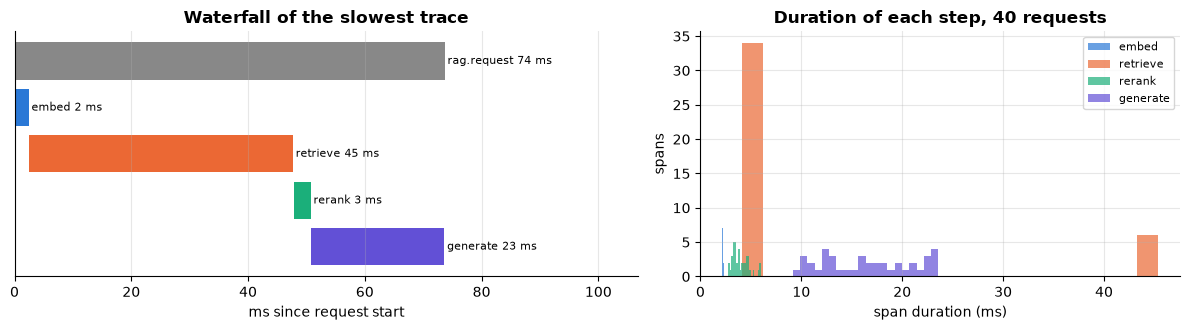

In [8]:
# Find the slowest request and explain it with its spans
roots = sp[sp.parent_id.isna()].sort_values("duration_ms", ascending=False)
slow_trace = roots.trace_id.iloc[0]
t = sp[sp.trace_id == slow_trace].sort_values("start").copy()
t["offset_ms"] = (t.start - t.start.min()) * 1e3
children = t[t.parent_id.notna()]
slowest_child = children.loc[children.duration_ms.idxmax()]
print(f"slowest request: trace {slow_trace[:12]}…, {roots.duration_ms.iloc[0]:.1f} ms; "
      f"slowest step: '{slowest_child['name']}' ({slowest_child.duration_ms:.1f} ms, cache_hit={slowest_child.get('retrieval.cache_hit')})")

# Which attribute explains the slow retrievals across ALL traces?
ret = sp[sp.name == "retrieve"]
print("\nretrieve latency by cache hit:"); print(ret.groupby("retrieval.cache_hit").duration_ms.describe()[["count", "mean", "max"]].round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
colors = {"rag.request": "#888888", "embed": "#2a78d6", "retrieve": "#eb6834", "rerank": "#1baf7a", "generate": "#6250d6"}
for i, (_, row) in enumerate(t.iterrows()):
    axes[0].barh(i, row.duration_ms, left=row.offset_ms, color=colors[row["name"]])
    axes[0].text(row.offset_ms + row.duration_ms + 0.5, i, f"{row['name']} {row.duration_ms:.0f} ms", va="center", fontsize=8)
axes[0].set_yticks([]); axes[0].invert_yaxis(); axes[0].set_xlabel("ms since request start")
axes[0].set_title("Waterfall of the slowest trace"); axes[0].set_xlim(0, t.duration_ms.max() * 1.45)
for name in ["embed", "retrieve", "rerank", "generate"]:
    axes[1].hist(sp[sp.name == name].duration_ms, bins=20, alpha=0.7, label=name, color=colors[name])
axes[1].set_xlabel("span duration (ms)"); axes[1].set_ylabel("spans"); axes[1].set_title("Duration of each step, 40 requests")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**What just happened?** The summary table shows `retrieve` has by far the widest spread (its p95 and max are much larger than its median), and the waterfall of the slowest trace shows a cache-missing `retrieve` span dominating that request. Grouping the `retrieve` spans by their `retrieval.cache_hit` **attribute** turns "some requests are slow" into "cache misses are slow": that is the power of attributes on spans. A metric could tell you p95 latency went up; only traces tell you which step and which kind of request.

**Context propagation and log correlation.** In a real system, `rag-api` would call a separate model server over HTTP. The caller **injects** the trace context into the request headers and the callee **extracts** it, so both sides' spans join one trace. Our JSON logs also picked up the active trace ID automatically.

In [9]:
EXPORTER.clear()
propagator = TraceContextTextMapPropagator()
with tracer.start_as_current_span("gateway.handle") as gw:
    headers = {}
    propagator.inject(headers)                                    # what goes over the wire
    sent_trace = format(gw.get_span_context().trace_id, "032x")
print("HTTP header sent to the model server:", headers)

ctx = propagator.extract(headers)                                 # ...on the other side of the network
with tracer.start_as_current_span("model_server.predict", context=ctx) as ms:
    log_event("model_server_called", note="this log line carries the same trace_id")
received_trace = format(ms.get_span_context().trace_id, "032x")
print("same trace ID on both sides:", sent_trace == received_trace)

last = json.loads(LOG_BUFFER.getvalue().splitlines()[-1])
print("log line:", {k: last[k] for k in ("event", "trace_id")})
assert sent_trace == received_trace == last["trace_id"]

HTTP header sent to the model server: {'traceparent': '00-ef0a81ed3d5d60bcbb0378eb7a62722e-4ed135530c5a876f-03'}
same trace ID on both sides: True
log line: {'event': 'model_server_called', 'trace_id': 'ef0a81ed3d5d60bcbb0378eb7a62722e'}


**What just happened?** The `traceparent` header carried the trace ID from the "gateway" to the "model server", whose span became a child in the same trace, and the log line written inside that span carries the same `trace_id`. With logs, traces and metrics all keyed by these IDs (and metrics optionally carrying **exemplars**, links from a histogram bucket to an example trace), you can jump from "p99 is high" to a slow trace to its log lines in three clicks.

⚠️ **Common mistake:** tracing 100% of traffic forever. Traces are large; production systems **sample** (e.g. keep 1–10%), ideally with **tail-based sampling**, which decides after the request finishes so that every error and slow request is kept.

## 5. SLIs, SLOs, error budgets and burn-rate alerts

> 💬 **In plain English:** turn a reliability promise into an error budget and alert only when the budget burns too fast.

**Definitions (Google SRE book and workbook).**
- **SLI** (service level indicator): a ratio of good events to valid events, e.g. the fraction of requests that succeed **and** finish in under 800 ms.
- **SLO** (service level objective): a target for an SLI over a window, e.g. 99.5% over 30 days. (An **SLA** is a contract with penalties, usually looser than the SLO.)
- **Error budget** $= 1 - \text{SLO}$: the fraction of events allowed to be bad. 99.5% over 30 days = 0.5% of requests, or 216 minutes of total outage ($0.005 \times 43{,}200$ min).
- **Burn rate** = observed bad fraction ÷ error budget. A burn rate of 1 uses exactly the whole budget over the window; a burn rate of 14.4 sustained for 1 hour uses $14.4 / 720 = 2\%$ of a 30-day budget.

**Multi-window, multi-burn-rate alerts** (SRE Workbook ch. 5): page only when the budget burns fast over a **long** window (so the problem is significant) **and** a **short** window (so it is still happening):

| Severity | Long window | Short window | Burn rate | Budget used when it fires |
|---|---|---|---|---|
| page | 1 hour | 5 min | 14.4 | 2% |
| page | 6 hours | 30 min | 6 | 5% |
| ticket | 3 days | 6 hours | 1 | 10% |

We generate 30 days of minute-level traffic with daily seasonality, a 0.1% background error rate and three incidents: a 3-minute blip (10% errors), a 30-minute outage (50% errors), and a 36-hour slow burn (1.2% errors). Then we compare these rules with a naive "error rate over the last 5 minutes > 0.5%" alert.

In [10]:
SLO = 0.995
BUDGET = 1 - SLO
MIN_PER_DAY, DAYS = 1440, 30
T = MIN_PER_DAY * DAYS
srng = np.random.default_rng(5)
minute = np.arange(T)
traffic = srng.poisson(200 * (1 + 0.5 * np.sin(2 * np.pi * (minute / MIN_PER_DAY - 0.3))))   # requests per minute
p_err = np.full(T, 0.001)
INCIDENTS = {"blip (3 min, 10%)": (5 * 1440 + 9 * 60, 3, 0.10),
             "outage (30 min, 50%)": (10 * 1440 + 14 * 60, 30, 0.50),
             "slow burn (36 h, 1.2%)": (20 * 1440 + 6 * 60, 36 * 60, 0.012)}
for start, length, p in INCIDENTS.values():
    p_err[start:start + length] = p
errors = srng.binomial(traffic, p_err)

def window_burn(errors, traffic, w):
    """Burn rate over a trailing window of w minutes, for every minute."""
    ce, ct = np.concatenate([[0], np.cumsum(errors)]), np.concatenate([[0], np.cumsum(traffic)])
    idx = np.arange(1, len(errors) + 1)
    lo = np.maximum(idx - w, 0)
    return ((ce[idx] - ce[lo]) / np.maximum(ct[idx] - ct[lo], 1)) / BUDGET

burn = {w: window_burn(errors, traffic, w) for w in [5, 30, 60, 360, 4320]}
page = ((burn[60] > 14.4) & (burn[5] > 14.4)) | ((burn[360] > 6) & (burn[30] > 6))
ticket = (burn[4320] > 1) & (burn[360] > 1)
naive = burn[5] * BUDGET > 0.005                                           # 5-minute error rate above 0.5%

def episodes(flag):
    """Group consecutive firing minutes into alert episodes: list of (start, end)."""
    d = np.diff(np.concatenate([[0], flag.astype(int), [0]]))
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))

def describe(flag):
    eps = episodes(flag)
    rows = []
    for name, (start, length, p) in INCIDENTS.items():
        hit = [s for s, e in eps if start <= s <= start + length + 60]
        rows.append((name, f"{hit[0] - start} min" if hit else "not alerted"))
    real = sum(1 for s, e in eps if any(st <= s <= st + ln + 60 for st, ln, _ in INCIDENTS.values()))
    return len(eps), len(eps) - real, rows

for label, flag in [("multi-window page", page), ("multi-window ticket", ticket), ("naive 5-min > 0.5%", naive)]:
    n_eps, false_eps, rows = describe(flag)
    print(f"{label:22s}: {n_eps:3d} alert episodes, {false_eps:3d} not caused by an incident | detection delay: "
          + ", ".join(f"{n.split(' (')[0]} {d}" for n, d in rows))

budget_used = errors.sum() / (BUDGET * traffic.sum())
print(f"\nerror budget used over 30 days: {100 * budget_used:.0f}%")
for name, (start, length, p) in INCIDENTS.items():
    print(f"  {name:24s} used {100 * errors[start:start + length].sum() / (BUDGET * traffic.sum()):.1f}% of the budget")

multi-window page     :   1 alert episodes,   0 not caused by an incident | detection delay: blip not alerted, outage 8 min, slow burn not alerted
multi-window ticket   :   2 alert episodes,   0 not caused by an incident | detection delay: blip not alerted, outage 22 min, slow burn 1595 min
naive 5-min > 0.5%    : 119 alert episodes,  97 not caused by an incident | detection delay: blip 0 min, outage 0 min, slow burn 1 min

error budget used over 30 days: 43%
  blip (3 min, 10%)        used 0.2% of the budget
  outage (30 min, 50%)     used 10.4% of the budget
  slow burn (36 h, 1.2%)   used 13.1% of the budget


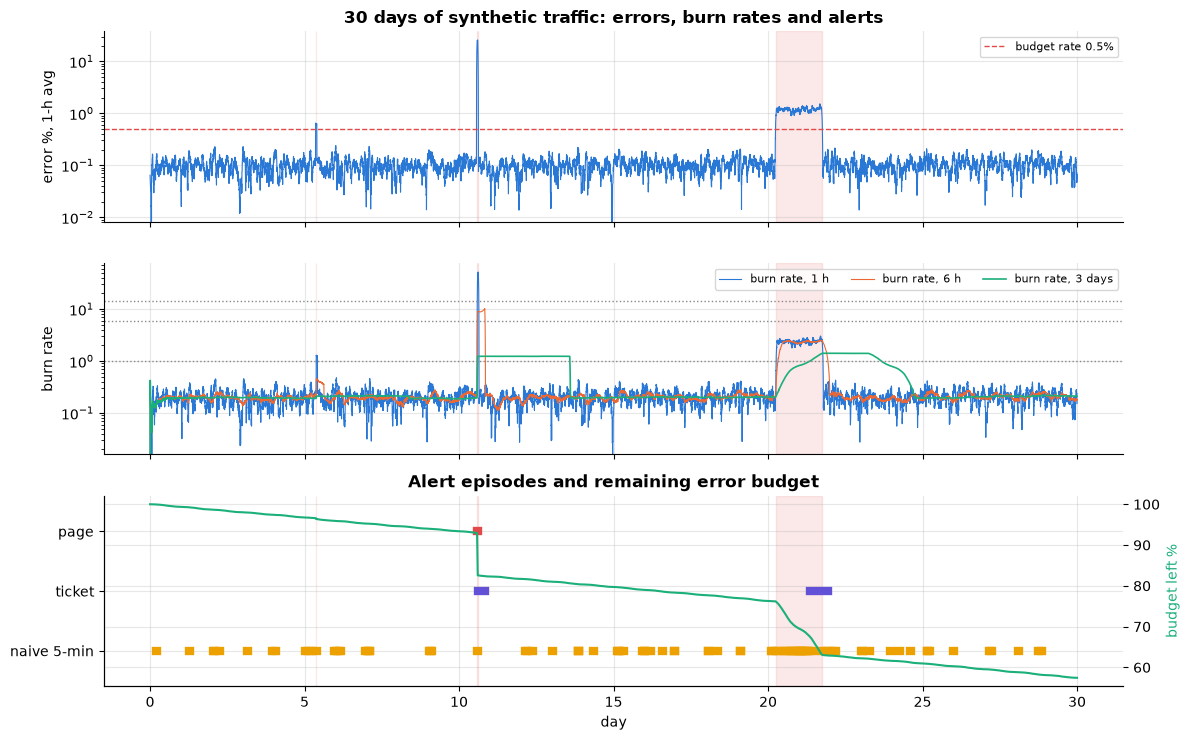

In [11]:
days = minute / MIN_PER_DAY
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
axes[0].plot(days, 100 * np.convolve(errors, np.ones(60), "same") / np.maximum(np.convolve(traffic, np.ones(60), "same"), 1), lw=0.8)
axes[0].axhline(100 * BUDGET, color="#e34948", ls="--", lw=1, label="budget rate 0.5%")
axes[0].set_ylabel("error %, 1-h avg"); axes[0].set_yscale("log"); axes[0].legend(fontsize=8)
axes[0].set_title("30 days of synthetic traffic: errors, burn rates and alerts")
axes[1].plot(days, burn[60], lw=0.8, label="burn rate, 1 h"); axes[1].plot(days, burn[360], lw=0.8, label="burn rate, 6 h")
axes[1].plot(days, burn[4320], lw=1.2, label="burn rate, 3 days")
for th in (14.4, 6, 1):
    axes[1].axhline(th, color="#888", ls=":", lw=1)
axes[1].set_yscale("log"); axes[1].set_ylabel("burn rate"); axes[1].legend(fontsize=8, ncol=3)
for k, (label, flag, c) in enumerate([("naive", naive, "#eda100"), ("ticket", ticket, "#6250d6"), ("page", page, "#e34948")]):
    for s, e in episodes(flag):
        axes[2].plot([s / MIN_PER_DAY, max(e, s + 30) / MIN_PER_DAY], [k, k], color=c, lw=6)
axes[2].set_yticks([0, 1, 2]); axes[2].set_yticklabels(["naive 5-min", "ticket", "page"]); axes[2].set_ylim(-0.6, 2.6)
ax2 = axes[2].twinx(); ax2.plot(days, 100 * (1 - np.cumsum(errors) / (BUDGET * traffic.sum())), color="#1baf7a", lw=1.5)
ax2.set_ylabel("budget left %", color="#1baf7a"); axes[2].set_xlabel("day"); axes[2].set_title("Alert episodes and remaining error budget")
for start, length, _ in INCIDENTS.values():
    for ax in axes:
        ax.axvspan(start / MIN_PER_DAY, (start + length) / MIN_PER_DAY, color="#e34948", alpha=0.12)
plt.tight_layout(); plt.show()

**What just happened?** (Exact counts and delays are printed above the chart.)
- The **page** rules fired for the 30-minute outage within minutes and stayed silent for the 3-minute blip, which consumed only a sliver of the budget: nobody needs to be woken up for it.
- The 36-hour **slow burn** never burns fast enough to page, but the **ticket** rule (3 days and 6 hours above burn rate 1) caught it after about a day. It used more budget than the dramatic outage did, which is exactly the case a fast-burn alert misses.
- The **naive** 5-minute threshold fired on all three incidents but also produced many alert episodes not caused by any incident: with only a few hundred requests in 5 minutes, a handful of chance errors pushes the 5-minute error rate over 0.5%, especially when traffic is low. Alert fatigue like this is how real incidents get ignored.

🎓 **Interview tip:** "How would you alert on an ML API?" Define SLIs from the user's point of view (success and latency), set an SLO, alert on **burn rate** over two windows, page for fast burns, ticket for slow ones, and route everything else to dashboards.

## 6. ML-specific monitors: drift, delayed labels and alert thresholds

> 💬 **In plain English:** watch the model's inputs, outputs and (late-arriving) labels, with thresholds set by how often you can afford a false alarm.

A model can satisfy every latency and error SLO while its answers get worse. ML monitors watch three things:

| What changed | Detectable without labels? | Monitor |
|---|---|---|
| inputs $P(X)$ (**data / covariate drift**) | yes | per-feature PSI, KS; multivariate MMD |
| outputs $P(\hat{y})$ (**prediction drift**) | yes | PSI / KS on scores; share of each class |
| relationship $P(Y \mid X)$ (**concept drift**) | **no**, needs labels | accuracy, AUC, calibration on labelled data, often **delayed** |

**Definitions.**
- **PSI** (population stability index) over $B$ bins with reference shares $q_i$ and current shares $p_i$: $\text{PSI} = \sum_i (p_i - q_i) \ln(p_i / q_i)$. Bins are usually reference deciles.
- **KS statistic**: $D = \sup_x |F_{\text{ref}}(x) - F_{\text{cur}}(x)|$, the largest gap between the two empirical CDFs.
- **MMD** (maximum mean discrepancy, Gretton et al. 2012): the distance between the mean embeddings of two samples under a kernel $k$. Unbiased estimate: $\widehat{\text{MMD}}^2 = \overline{k(x, x')} + \overline{k(y, y')} - 2\,\overline{k(x, y)}$ (excluding $i = j$ terms). With an RBF kernel it detects **any** difference in distribution, including changes in correlation that per-feature tests miss. A **permutation test** gives a p-value.

In [12]:
def psi(ref, cur, bins=10, eps=1e-4):
    """PSI with reference-quantile bins."""
    edges = np.quantile(ref, np.linspace(0, 1, bins + 1))[1:-1]          # inner edges; outer bins are open
    q = np.bincount(np.searchsorted(edges, ref, side="right"), minlength=bins) / len(ref)
    p = np.bincount(np.searchsorted(edges, cur, side="right"), minlength=bins) / len(cur)
    q, p = np.maximum(q, eps), np.maximum(p, eps)
    return float(np.sum((p - q) * np.log(p / q)))

def ks_stat(a, b):
    """Two-sample Kolmogorov-Smirnov statistic from the merged sorted sample."""
    a, b = np.sort(a), np.sort(b)
    grid = np.concatenate([a, b])
    return float(np.max(np.abs(np.searchsorted(a, grid, side="right") / len(a) - np.searchsorted(b, grid, side="right") / len(b))))

def mmd2_perm_test(X, Y, n_perm=200, seed=0):
    """Unbiased MMD^2 with an RBF kernel (median-distance bandwidth) and a permutation p-value."""
    Z = np.vstack([X, Y]); n = len(X)
    D2 = ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(-1)
    K = np.exp(-D2 / np.median(D2[D2 > 0]))
    def stat(idx):
        a, b = idx[:n], idx[n:]
        Kxx, Kyy, Kxy = K[np.ix_(a, a)], K[np.ix_(b, b)], K[np.ix_(a, b)]
        m = len(b)
        return (Kxx.sum() - np.trace(Kxx)) / (n * (n - 1)) + (Kyy.sum() - np.trace(Kyy)) / (m * (m - 1)) - 2 * Kxy.mean()
    rng = np.random.default_rng(seed)
    observed = stat(np.arange(len(Z)))
    null = [stat(rng.permutation(len(Z))) for _ in range(n_perm)]
    return observed, (1 + sum(v >= observed for v in null)) / (1 + n_perm)

drng = np.random.default_rng(6)
ref = drng.normal(size=5000)
for shift in [0.0, 0.2, 0.5]:
    cur = drng.normal(loc=shift, size=1000)
    ks_ours, ks_scipy = ks_stat(ref, cur), stats.ks_2samp(ref, cur)
    assert math.isclose(ks_ours, ks_scipy.statistic)
    print(f"mean shift {shift}: PSI {psi(ref, cur):.3f} | KS D {ks_ours:.3f} (scipy p-value {ks_scipy.pvalue:.2g})")

# A drift that per-feature tests cannot see: same marginals, different correlation
X_ref = drng.multivariate_normal([0, 0], [[1, 0], [0, 1]], 300)
X_cur = drng.multivariate_normal([0, 0], [[1, 0.8], [0.8, 1]], 300)
print("\ncorrelation drift (marginals unchanged):")
for j in range(2):
    print(f"  feature {j}: PSI {psi(X_ref[:, j], X_cur[:, j]):.3f}, KS p-value {stats.ks_2samp(X_ref[:, j], X_cur[:, j]).pvalue:.2f}")
for label, A, B in [("no drift   ", X_ref[:150], X_ref[150:]), ("correlation", X_ref, X_cur)]:
    mmd, pval = mmd2_perm_test(A, B)
    print(f"  MMD² {label}: {mmd:.4f}, permutation p-value {pval:.3f}")

mean shift 0.0: PSI 0.005 | KS D 0.019 (scipy p-value 0.93)
mean shift 0.2: PSI 0.028 | KS D 0.072 (scipy p-value 0.00034)
mean shift 0.5: PSI 0.228 | KS D 0.194 (scipy p-value 6.8e-28)

correlation drift (marginals unchanged):
  feature 0: PSI 0.048, KS p-value 0.15
  feature 1: PSI 0.041, KS p-value 0.15
  MMD² no drift   : -0.0004, permutation p-value 0.413


  MMD² correlation: 0.0380, permutation p-value 0.005


**What just happened?** Our KS statistic equals SciPy's exactly (asserted), and PSI and KS both grow with the size of the mean shift. The second experiment is the important one: when only the **correlation** between two features changes, each feature on its own still looks standard normal, so per-feature PSI and KS see nothing unusual, while the multivariate **MMD** permutation test flags the change (a small p-value), and on two halves of the reference sample it does not. (The unbiased MMD² estimate can come out slightly negative when the two samples come from the same distribution; only its size relative to the permutation null matters.) Use per-feature tests for explainability ("which feature moved?") and a multivariate test as a safety net.

### 6.1 Choosing thresholds: how often will this alarm lie?

The popular rule of thumb "PSI > 0.1 = investigate, > 0.2 = act" (used in `06_monitoring`) ignores **sample size**: with a small window, PSI is noisy even when nothing changed. The principled approach is to simulate PSI under **no drift** for your window size, pick the threshold that gives an acceptable **false-alarm rate** (say 1% of windows), and then check the **power** (detection probability) for the shifts you care about.

 window size n  false alarms at 0.1  false alarms at 0.2  threshold for 1% false alarms  approx. mean PSI under no drift (B-1)(1/n+1/N)
           100                0.401                 0.03                         0.2503                                          0.0909
           500                0.000                 0.00                         0.0435                                          0.0189
          2000                0.000                 0.00                         0.0127                                          0.0054


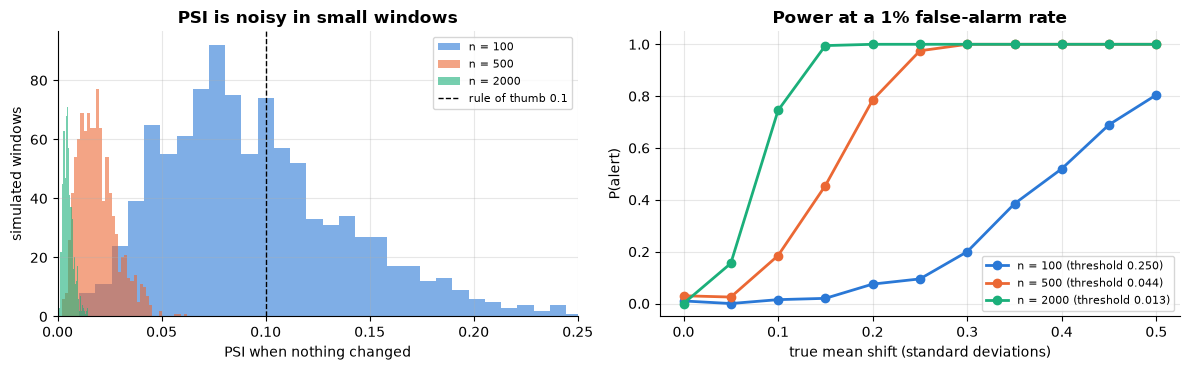

In [13]:
frng = np.random.default_rng(7)
ref_big = frng.normal(size=10_000)
rows, null_psi = [], {}
for n in [100, 500, 2000]:
    null_psi[n] = np.array([psi(ref_big, frng.normal(size=n)) for _ in range(1000)])
    rows.append((n, np.mean(null_psi[n] > 0.1), np.mean(null_psi[n] > 0.2), np.quantile(null_psi[n], 0.99), 9 * (1 / n + 1 / 10_000)))
far = pd.DataFrame(rows, columns=["window size n", "false alarms at 0.1", "false alarms at 0.2", "threshold for 1% false alarms",
                                  "approx. mean PSI under no drift (B-1)(1/n+1/N)"]).round(4)
print(far.to_string(index=False))

shifts = np.linspace(0, 0.5, 11)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for n, c in zip([100, 500, 2000], ["#2a78d6", "#eb6834", "#1baf7a"]):
    axes[0].hist(null_psi[n], bins=40, alpha=0.6, color=c, label=f"n = {n}")
    thr = np.quantile(null_psi[n], 0.99)
    power = [np.mean([psi(ref_big, frng.normal(loc=s, size=n)) > thr for _ in range(200)]) for s in shifts]
    axes[1].plot(shifts, power, "o-", color=c, label=f"n = {n} (threshold {thr:.3f})")
axes[0].axvline(0.1, color="k", ls="--", lw=1, label="rule of thumb 0.1")
axes[0].set_xlabel("PSI when nothing changed"); axes[0].set_ylabel("simulated windows"); axes[0].set_title("PSI is noisy in small windows")
axes[0].legend(fontsize=8); axes[0].set_xlim(0, 0.25)
axes[1].set_xlabel("true mean shift (standard deviations)"); axes[1].set_ylabel("P(alert)")
axes[1].set_title("Power at a 1% false-alarm rate"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?** With 100 samples per window, PSI exceeds the 0.1 rule-of-thumb in a sizeable share of windows **even though nothing changed** (first table column), so a daily check would cry wolf regularly; with 2,000 samples the same threshold almost never fires falsely, but it also misses moderate shifts it could easily detect. The simulated thresholds for a 1% false-alarm rate shrink roughly in proportion to $1/n$ as the window grows, like the mean PSI under no drift in the last column. The power curves show the trade-off: bigger windows detect smaller shifts, at the cost of reacting later. Pick the window from how fast you must react, then the threshold from the false-alarm rate you can afford.

### 6.2 Delayed labels: performance you can only see later

In fraud, credit or churn, the true label arrives days to months after the prediction. A monitor must then combine **label-free** signals (input and prediction drift, available immediately) with **label-based** performance (accurate but late). Below: 40 days of traffic, a **covariate shift** in feature 0 from day 12, a **concept drift** (the relationship between features and label changes) from day 24, and labels that arrive **7 days** late. "Today" is day 35.

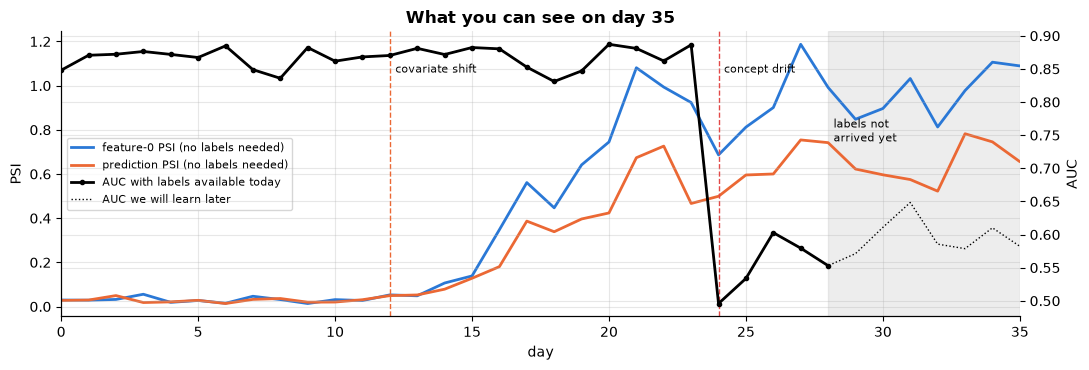

 day  score PSI  feature-0 PSI   AUC  AUC known today
  10      0.020          0.031 0.862            0.862
  14      0.079          0.107 0.872            0.872
  20      0.424          0.745 0.887            0.887
  23      0.467          0.924 0.886            0.886
  25      0.596          0.812 0.534            0.534
  28      0.742          0.992 0.553            0.553
  30      0.596          0.897 0.611              NaN


In [14]:
lrng = np.random.default_rng(8)
w_true = np.array([1.5, -1.0, 0.8, 0.0])
ref_X = lrng.normal(size=(4000, 4))                                     # the training-time data
ref_y = (lrng.random(4000) < 1 / (1 + np.exp(-(ref_X @ w_true)))).astype(int)
drift_model = LogisticRegression().fit(ref_X, ref_y)
ref_scores = drift_model.predict_proba(ref_X)[:, 1]
rows = []
for day in range(40):
    Xd = lrng.normal(size=(400, 4))
    if day >= 12:
        Xd[:, 0] += min(1.0, 0.1 * (day - 11))                         # covariate shift ramps up
    w = w_true if day < 24 else np.array([-0.5, -1.0, 0.8, 1.2])         # concept drift: the rules change
    yd = (lrng.random(400) < 1 / (1 + np.exp(-(Xd @ w)))).astype(int)
    scores = drift_model.predict_proba(Xd)[:, 1]
    rows.append((day, psi(ref_scores, scores), psi(ref_X[:, 0], Xd[:, 0]), roc_auc_score(yd, scores)))
daily = pd.DataFrame(rows, columns=["day", "score PSI", "feature-0 PSI", "AUC"])
TODAY, DELAY = 35, 7
daily["AUC known today"] = np.where(daily.day <= TODAY - DELAY, daily.AUC, np.nan)

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.day, daily["feature-0 PSI"], label="feature-0 PSI (no labels needed)")
ax.plot(daily.day, daily["score PSI"], label="prediction PSI (no labels needed)")
ax2 = ax.twinx()
ax2.plot(daily.day, daily["AUC known today"], "k-o", ms=3, label="AUC with labels available today")
ax2.plot(daily.day, daily.AUC, "k:", lw=1, label="AUC we will learn later")
ax.axvline(12, color="#eb6834", ls="--", lw=1); ax.text(12.2, ax.get_ylim()[1] * 0.85, "covariate shift", fontsize=8)
ax.axvline(24, color="#e34948", ls="--", lw=1); ax.text(24.2, ax.get_ylim()[1] * 0.85, "concept drift", fontsize=8)
ax.axvspan(TODAY - DELAY, TODAY, color="#888", alpha=0.15); ax.text(TODAY - DELAY + 0.2, ax.get_ylim()[1] * 0.6, "labels not\narrived yet", fontsize=8)
ax.set_xlabel("day"); ax.set_ylabel("PSI"); ax2.set_ylabel("AUC"); ax.set_xlim(0, TODAY)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="center left"); ax.set_title("What you can see on day 35")
plt.tight_layout(); plt.show()
print(daily.iloc[[10, 14, 20, 23, 25, 28, 30]].round(3).to_string(index=False))

**What just happened?** The covariate shift from day 12 shows up **immediately** in the feature PSI and in the prediction PSI, no labels needed. The concept drift from day 24 does not change the inputs at all, so it adds nothing to either PSI (they stay at the level the earlier covariate shift caused); it only shows up as a falling AUC, and with a 7-day label delay, on day 35 we can see AUC only up to day 28 (solid line). The dotted line is what we will learn later. Lessons: (1) label-free monitors are early warnings for **input** changes, not proof of lower accuracy (the AUC here stayed fairly stable during the covariate shift); (2) concept drift needs labels, so shorten the label delay where possible (proxy labels, human review of a sample, fast-feedback signals such as user clicks).

## 7. Dashboards as code

> 💬 **In plain English:** describe the dashboard as code (Grafana JSON) and draw the same panels.

**Dashboards as code:** keep dashboard definitions in version control as JSON (Grafana) or code (Grafonnet, the Grafana Terraform provider), reviewed like any other change. A good service dashboard reads top to bottom: **is it up** (SLO, budget) → **RED** (rate, errors, duration) → **saturation** (USE) → **ML health** (drift, model version).

Below is a Grafana dashboard described as a Python dict and saved as JSON (illustrative; Grafana's schema has more optional fields and changes between versions, and you would import it via *Dashboards → New → Import*). The PromQL queries use the metric names our service exports in section 3. Then we render the same panels with matplotlib from the synthetic data of sections 5 and 6.

In [15]:
def panel(pid, title, ptype, expr, unit, x, y, w=12, h=8):
    return {"id": pid, "title": title, "type": ptype, "datasource": {"type": "prometheus", "uid": "${datasource}"},
            "targets": [{"expr": expr, "refId": "A"}], "fieldConfig": {"defaults": {"unit": unit}},
            "gridPos": {"x": x, "y": y, "w": w, "h": h}}

dashboard = {
    "title": "Prediction service: SLO, RED and drift",
    "uid": "pred-svc-obs16", "schemaVersion": 39, "refresh": "1m", "time": {"from": "now-24h", "to": "now"},
    "tags": ["ml", "slo"],
    "templating": {"list": [{"name": "datasource", "type": "datasource", "query": "prometheus"}]},
    "panels": [
        panel(1, "Error budget remaining (30 d)", "stat",
              '1 - (sum(increase(predict_requests_total{status=~"5.."}[30d])) / sum(increase(predict_requests_total[30d]))) / 0.005',
              "percentunit", 0, 0, 6, 6),
        panel(2, "Burn rate (1 h)", "stat",
              '(sum(rate(predict_requests_total{status=~"5.."}[1h])) / sum(rate(predict_requests_total[1h]))) / 0.005',
              "none", 6, 0, 6, 6),
        panel(3, "Request rate (R)", "timeseries", "sum(rate(predict_requests_total[5m]))", "reqps", 12, 0, 12, 6),
        panel(4, "Error ratio (E)", "timeseries",
              'sum(rate(predict_requests_total{status=~"5.."}[5m])) / sum(rate(predict_requests_total[5m]))',
              "percentunit", 0, 6),
        panel(5, "Latency p50 / p95 / p99 (D)", "timeseries",
              "histogram_quantile(0.95, sum by (le) (rate(predict_latency_seconds_bucket[5m])))", "s", 12, 6),
        panel(6, "Feature drift (PSI, daily)", "timeseries", "max by (feature) (feature_psi)", "none", 0, 14),
        panel(7, "Model version in production", "table", "model_info", "none", 12, 14),
    ],
}
path = WORK / "prediction_service_dashboard.json"
path.write_text(json.dumps(dashboard, indent=2))
loaded = json.loads(path.read_text())
assert {p["id"] for p in loaded["panels"]} == set(range(1, 8))
print(f"wrote {path.name}: {len(loaded['panels'])} panels, {path.stat().st_size:,} bytes")
for p in loaded["panels"]:
    print(f"  [{p['type']:10s}] {p['title']:34s} {p['targets'][0]['expr'][:70]}")

wrote prediction_service_dashboard.json: 7 panels, 4,090 bytes
  [stat      ] Error budget remaining (30 d)      1 - (sum(increase(predict_requests_total{status=~"5.."}[30d])) / sum(i
  [stat      ] Burn rate (1 h)                    (sum(rate(predict_requests_total{status=~"5.."}[1h])) / sum(rate(predi
  [timeseries] Request rate (R)                   sum(rate(predict_requests_total[5m]))
  [timeseries] Error ratio (E)                    sum(rate(predict_requests_total{status=~"5.."}[5m])) / sum(rate(predic
  [timeseries] Latency p50 / p95 / p99 (D)        histogram_quantile(0.95, sum by (le) (rate(predict_latency_seconds_buc
  [timeseries] Feature drift (PSI, daily)         max by (feature) (feature_psi)
  [table     ] Model version in production        model_info


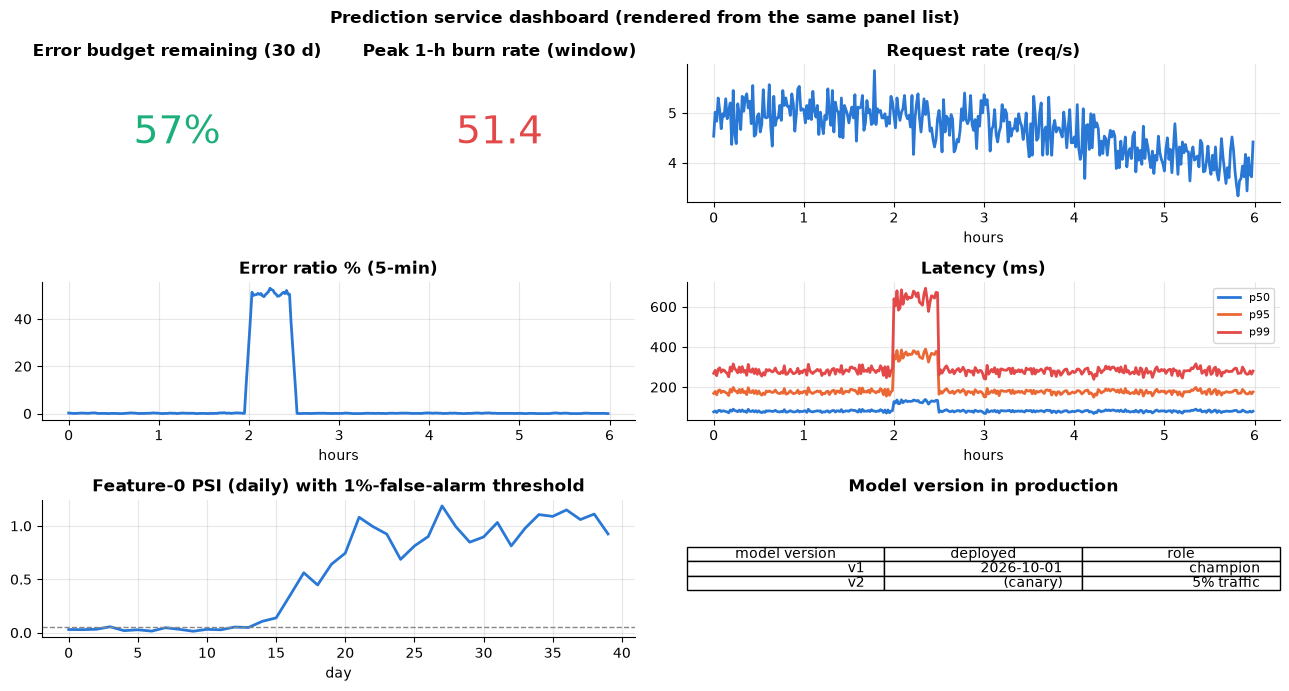

In [16]:
# The same panels drawn from the synthetic 30-day stream (around the outage) and the drift data
win = slice(10 * 1440 + 12 * 60, 10 * 1440 + 18 * 60)                          # 6 hours around the outage
t_h = (minute[win] - minute[win][0]) / 60
normal_mult, outage_mult = {0.5: 1.0, 0.95: 2.2, 0.99: 3.5}, {0.5: 1.6, 0.95: 4.5, 0.99: 8.0}
lat_p = {q: 0.08 * np.where(p_err[win] > 0.1, outage_mult[q], normal_mult[q]) * (1 + 0.05 * np.random.default_rng(9).normal(size=len(t_h)))
         for q in (0.5, 0.95, 0.99)}                                              # illustrative latency lines
fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(3, 4)
ax = fig.add_subplot(gs[0, 0]); ax.axis("off")
ax.text(0.5, 0.5, f"{100 * (1 - budget_used):.0f}%", ha="center", va="center", fontsize=28, color="#1baf7a")
ax.set_title("Error budget remaining (30 d)")
ax = fig.add_subplot(gs[0, 1]); ax.axis("off")
ax.text(0.5, 0.5, f"{burn[60][win].max():.1f}", ha="center", va="center", fontsize=28, color="#e34948")
ax.set_title("Peak 1-h burn rate (window)")
ax = fig.add_subplot(gs[0, 2:]); ax.plot(t_h, traffic[win] / 60); ax.set_title("Request rate (req/s)")
ax = fig.add_subplot(gs[1, :2]); ax.plot(t_h, 100 * np.convolve(errors[win], np.ones(5), "same") / np.convolve(traffic[win], np.ones(5), "same"))
ax.set_title("Error ratio % (5-min)")
ax = fig.add_subplot(gs[1, 2:])
for q, c in zip(lat_p, ["#2a78d6", "#eb6834", "#e34948"]):
    ax.plot(t_h, lat_p[q] * 1e3, color=c, label=f"p{int(q * 100)}")
ax.set_title("Latency (ms)"); ax.legend(fontsize=8)
thr400 = np.quantile([psi(ref_X[:, 0], np.random.default_rng(100 + k).normal(size=400)) for k in range(500)], 0.99)
ax = fig.add_subplot(gs[2, :2]); ax.plot(daily.day, daily["feature-0 PSI"]); ax.axhline(thr400, color="#888", ls="--", lw=1)
ax.set_title("Feature-0 PSI (daily) with 1%-false-alarm threshold"); ax.set_xlabel("day")
ax = fig.add_subplot(gs[2, 2:]); ax.axis("off")
ax.table(cellText=[["v1", "2026-10-01", "champion"], ["v2", "(canary)", "5% traffic"]],
         colLabels=["model version", "deployed", "role"], loc="center"); ax.set_title("Model version in production")
for a in fig.axes[2:5]:
    a.set_xlabel("hours")
fig.suptitle("Prediction service dashboard (rendered from the same panel list)", fontweight="bold")
plt.tight_layout(); plt.show()

**What just happened?** The dashboard exists twice: as reviewable JSON that Grafana can import, and as a matplotlib rendering of the same layout from our synthetic data. The top row answers "are we keeping our promise?" (budget, burn rate) before anyone looks at a graph; the middle row is RED; the bottom row is ML health. (The latency lines in this rendering are illustrative: the synthetic stream in section 5 modelled errors, not latencies.)

⚠️ **Common mistake:** dashboards with 40 panels and no story. Start from the questions an on-call engineer asks, in order, and delete panels nobody looks at during incidents.

## 8. Incident drill: a deploy meets a data shift

> 💬 **In plain English:** practise a real incident: detect, triage, diagnose, mitigate, and write the post-mortem.

**Scenario.** At 14:00 the RAG service's new release **v2** goes out. It contains a "harmless refactor" that removed the step truncating long queries to 128 tokens before reranking. The same afternoon a client team launches a "summarise this document" button, so prompts become much longer. We simulate 6 hours of traffic (minute level) and walk through a standard **runbook**: detect → triage → diagnose → mitigate → recover → post-mortem. (Process and post-mortem templates in depth: [`19_AI_Ethics_and_Safety/09`](../19_AI_Ethics_and_Safety/09_industry_ai_incident_response_and_red_teaming.ipynb).)

**Latency SLI:** fraction of requests completing in under 800 ms. **SLO:** 99% (budget 1%).

In [17]:
irng = np.random.default_rng(10)
DEPLOY, LAUNCH, ROLLBACK, MINUTES = 120, 135, None, 360          # minutes after 12:00
LAT_SLO_MS, LAT_BUDGET = 800, 0.01

def simulate_minute(m, version, rng):
    """Synthetic per-request latencies (ms) and prompt lengths for one minute of traffic."""
    n = rng.poisson(150)
    long_share = 0.35 if m >= LAUNCH else 0.02                     # the new client feature sends long documents
    tokens = np.where(rng.random(n) < long_share, rng.lognormal(math.log(900), 0.4, n), rng.lognormal(math.log(60), 0.5, n))
    rerank_tokens = tokens if version == "v2" else np.minimum(tokens, 128)
    lat = rng.lognormal(math.log(180), 0.3, n) + 20 * rerank_tokens * 0.045    # base + rerank cost (ms)
    return tokens, lat

def run_service(rollback_at=None):
    recs = []
    for m in range(MINUTES):
        version = "v2" if (m >= DEPLOY and (rollback_at is None or m < rollback_at)) else "v1"
        tokens, lat = simulate_minute(m, version, irng)
        recs.append((m, version, len(lat), int((lat > LAT_SLO_MS).sum()), np.percentile(lat, 95), tokens))
    return pd.DataFrame(recs, columns=["minute", "version", "requests", "slow", "p95_ms", "tokens"])

ops = run_service()                                                # first: what happens if nobody reacts
burn5 = window_burn(ops.slow.values, ops.requests.values, 5) * BUDGET / LAT_BUDGET
burn60 = window_burn(ops.slow.values, ops.requests.values, 60) * BUDGET / LAT_BUDGET
ops["page"] = (burn60 > 14.4) & (burn5 > 14.4)
ref_tokens = np.concatenate(ops.tokens[:DEPLOY].values)
ops["prompt_psi_30m"] = [psi(ref_tokens, np.concatenate(ops.tokens[max(0, m - 29):m + 1].values)) if m >= DEPLOY else np.nan
                         for m in range(MINUTES)]
first_page = int(ops.index[ops.page][0])
first_drift = int(ops.index[ops.prompt_psi_30m > 0.2][0])
fmt = lambda m: f"{12 + m // 60:02d}:{m % 60:02d}"
print(f"DETECT: deploy v2 at {fmt(DEPLOY)}, client launch at {fmt(LAUNCH)}")
print(f"  latency burn-rate page fired at {fmt(first_page)} ({first_page - LAUNCH} min after the launch)")
print(f"  prompt-length PSI > 0.2 at {fmt(first_drift)}")
print(ops.iloc[[100, 125, 140, 160, 200]][["minute", "version", "requests", "slow", "p95_ms", "prompt_psi_30m"]].round(2).to_string(index=False))

DETECT: deploy v2 at 14:00, client launch at 14:15
  latency burn-rate page fired at 14:45 (30 min after the launch)
  prompt-length PSI > 0.2 at 14:29
 minute version  requests  slow  p95_ms  prompt_psi_30m
    100      v1       173     0  360.60             NaN
    125      v2       158     2  384.14            0.00
    140      v2       129    31 1429.04            0.05
    160      v2       149    37 1329.78            0.47
    200      v2       185    45 1428.48            0.56


**Detect.** Two independent alerts fire within about half an hour of the client launch: the **prompt-length drift** monitor and then the latency **burn-rate page** (times printed above). Neither one alone says *why*.

**Triage: what changed?** The first question in every incident. Our structured logs (simulated here from the same traffic) can be grouped by version and prompt length in one line.

In [18]:
# TRIAGE: slice the request logs by what changed (version and input size)
log_rows = []
for _, r in ops.iloc[DEPLOY - 30:].iterrows():
    lat = np.random.default_rng(int(r.minute)).lognormal(math.log(180), 0.3, len(r.tokens))
    rerank_tokens = r.tokens if r.version == "v2" else np.minimum(r.tokens, 128)
    for tok, l in zip(r.tokens, lat + 20 * rerank_tokens * 0.045):
        log_rows.append((r.version, "long (>512)" if tok > 512 else "normal", l))
L = pd.DataFrame(log_rows, columns=["version", "prompt", "latency_ms"])
triage = L.groupby(["version", "prompt"]).latency_ms.agg(["count", "median", lambda s: (s > LAT_SLO_MS).mean()])
triage.columns = ["requests", "median ms", "share > 800 ms"]
print(triage.round(3).to_string())

# DIAGNOSE: traces of a few long-prompt requests on v1 and v2 (the real instrumented pipeline from section 4)
EXPORTER.clear()
trng = np.random.default_rng(11)
for version in ["v1", "v2"]:
    for _ in range(12):
        rag_request(int(trng.lognormal(math.log(900), 0.4)), trng, version=version, cache_miss_rate=0.0)
sp2 = spans_frame(EXPORTER.get_finished_spans())
roots2 = sp2[sp2.parent_id.isna()][["trace_id", "app.version"]]
sp2 = sp2.merge(roots2.rename(columns={"app.version": "version"}), on="trace_id")
diag = sp2[sp2.parent_id.notna()].pivot_table(index="name", columns="version", values="duration_ms", aggfunc="median").round(1)
print("\nmedian span duration (ms) for long prompts:"); print(diag.to_string())
assert diag.loc["rerank", "v2"] > 3 * diag.loc["rerank", "v1"]

                     requests  median ms  share > 800 ms
version prompt                                          
v1      long (>512)        75    301.469           0.000
        normal           4386    242.025           0.000
v2      long (>512)     11097   1039.255           0.822
        normal          24918    243.396           0.000



median span duration (ms) for long prompts:
version     v1    v2
name                
embed      3.8   4.1
generate  16.9  12.5
rerank     6.0  30.1
retrieve   4.2   4.2


**Diagnose.** The log slice shows the problem is specific to **long prompts on v2**: long prompts on v1 are fine and normal prompts on v2 are fine. The traces pin it to a single span: on v2, `rerank` takes several times longer for long prompts (its `rerank.tokens_per_pair` attribute shows it now scores the full prompt against all 20 candidates), while every other step is unchanged. Neither cause alone triggers the incident; their combination does, which is typical of real incidents.

**Mitigate first, fix later.** The fastest safe action is to **roll back to v1** (it truncates long queries); we can then fix v2 properly (restore truncation and add a load test with long prompts). Rolling back at 15:00:

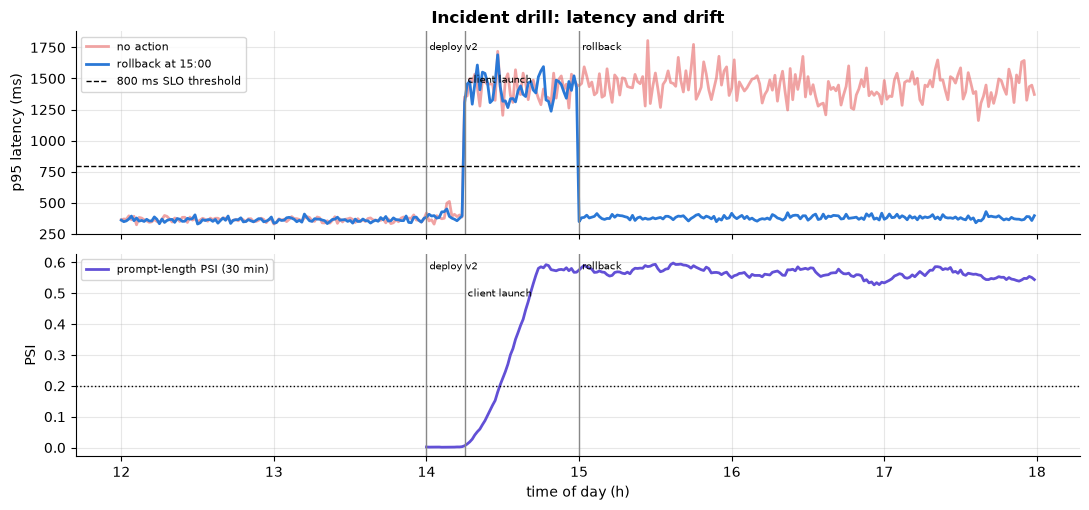

page cleared at 15:02; slow requests during the incident: 1,800 = 2.8% of a 30-day latency budget


In [19]:
MITIGATE = 180                                                    # 15:00: on-call rolls back to v1
fixed = run_service(rollback_at=MITIGATE)
b5 = window_burn(fixed.slow.values, fixed.requests.values, 5) * BUDGET / LAT_BUDGET
b60 = window_burn(fixed.slow.values, fixed.requests.values, 60) * BUDGET / LAT_BUDGET
fixed["page"] = (b60 > 14.4) & (b5 > 14.4)
recovered = int(fixed.index[(fixed.minute > MITIGATE) & ~fixed.page][0])

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
axes[0].plot(ops.minute / 60 + 12, ops.p95_ms, color="#e34948", alpha=0.5, label="no action")
axes[0].plot(fixed.minute / 60 + 12, fixed.p95_ms, color="#2a78d6", label="rollback at 15:00")
axes[0].axhline(LAT_SLO_MS, color="k", ls="--", lw=1, label="800 ms SLO threshold"); axes[0].set_ylabel("p95 latency (ms)")
axes[0].legend(fontsize=8); axes[0].set_title("Incident drill: latency and drift")
axes[1].plot(ops.minute / 60 + 12, ops.prompt_psi_30m, color="#6250d6", label="prompt-length PSI (30 min)")
axes[1].axhline(0.2, color="k", ls=":", lw=1); axes[1].set_ylabel("PSI"); axes[1].set_xlabel("time of day (h)"); axes[1].legend(fontsize=8)
for ax in axes:
    for m, lab, h in [(DEPLOY, "deploy v2", 0.92), (LAUNCH, "client launch", 0.78), (MITIGATE, "rollback", 0.92)]:
        ax.axvline(12 + m / 60, color="#888", lw=1); ax.text(12 + m / 60, ax.get_ylim()[1] * h, " " + lab, fontsize=7)
plt.tight_layout(); plt.show()

slow_total = fixed.slow[LAUNCH:].sum()
budget_month = LAT_BUDGET * 150 * 60 * 24 * 30                      # 30 days at ~150 requests/min
print(f"page cleared at {fmt(recovered)}; slow requests during the incident: {slow_total:,} "
      f"= {100 * slow_total / budget_month:.1f}% of a 30-day latency budget")

In [20]:
# POST-MORTEM (blameless), filled from the data above
timeline = pd.DataFrame([
    (fmt(DEPLOY), "v2 deployed (removed query truncation before rerank)"),
    (fmt(LAUNCH), "client team launches 'summarise this document': long prompts start"),
    (fmt(first_drift), "drift monitor: prompt-length PSI > 0.2"),
    (fmt(first_page), "PAGE: latency SLO burn rate > 14.4 over 1 h and 5 min"),
    (fmt(MITIGATE), "on-call rolls back to v1 after logs + traces point at v2 rerank on long prompts"),
    (fmt(recovered), "burn-rate page clears"),
], columns=["time", "event"])
print(timeline.to_string(index=False))
print(f"""
IMPACT       {slow_total:,} requests slower than 800 ms; {100 * slow_total / budget_month:.1f}% of the monthly latency budget.
ROOT CAUSE   v2 dropped the 128-token truncation before reranking; harmless for short prompts, so tests and the
             canary (short prompts only) passed. Long prompts from a new client feature made rerank cost explode.
WHAT WENT WELL    drift monitor and burn-rate page both fired within 30 minutes of the launch; traces localised the slow span.
WHAT WENT BADLY   no load test with long prompts; no cross-team notice of the client launch.
ACTIONS      (1) restore truncation + unit test on token limits; (2) add long-prompt cases to the load test;
             (3) add a prompt-length SLO dashboard panel; (4) require client launches to be announced to the API team.""")

 time                                                                           event
14:00                            v2 deployed (removed query truncation before rerank)
14:15              client team launches 'summarise this document': long prompts start
14:29                                          drift monitor: prompt-length PSI > 0.2
14:45                           PAGE: latency SLO burn rate > 14.4 over 1 h and 5 min
15:00 on-call rolls back to v1 after logs + traces point at v2 rerank on long prompts
15:02                                                           burn-rate page clears

IMPACT       1,800 requests slower than 800 ms; 2.8% of the monthly latency budget.
ROOT CAUSE   v2 dropped the 128-token truncation before reranking; harmless for short prompts, so tests and the
             canary (short prompts only) passed. Long prompts from a new client feature made rerank cost explode.
WHAT WENT WELL    drift monitor and burn-rate page both fired within 30 minutes of the 

**What just happened?** The drill went through the full loop with real tooling from this notebook: alerts from burn rates and PSI, triage by slicing structured logs, diagnosis from span-level traces, mitigation by rollback (latency recovered within minutes), and a blameless post-mortem whose timeline and impact numbers were computed rather than remembered. The action items fix the **system** (tests, guards, communication), not the person who merged the refactor.

## 🔗 How this connects to modern AI

| Observability idea | In LLM and ML systems |
|---|---|
| Traces with GenAI attributes | LLM observability tools (Langfuse, Arize Phoenix, LangSmith, OpenLLMetry) are built on OpenTelemetry-style traces of prompts, retrieval, tool calls and generations ([`13_llmops`](13_llmops.ipynb)) |
| Token and cost metrics | per-tenant cost dashboards, rate limiting, capacity planning for GPU fleets |
| Latency SLOs on percentiles | time to first token (TTFT) and inter-token latency SLOs for chat products ([`08_LLM/13`](../08_LLM/13_inference_optimization.ipynb)) |
| Drift monitors | embedding drift on RAG queries (MMD on embeddings), topic drift in prompts, retrieval hit-rate drops |
| Delayed labels | human feedback (thumbs up/down), LLM-as-judge sampling and annotation queues as faster "labels" |
| Burn-rate alerting, post-mortems | the same SRE practice used for LLM APIs; AI incident databases extend post-mortems to harms ([`19_AI_Ethics_and_Safety/09`](../19_AI_Ethics_and_Safety/09_industry_ai_incident_response_and_red_teaming.ipynb)) |
| Safe rollouts | canaries and automatic rollback driven by these SLOs ([`16_Deployment/05`](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb)) |

## Recap

- **Logs** (events), **metrics** (aggregated numbers) and **traces** (per-request timelines) answer different questions; use RED for services and USE for resources, and add model version, input hash, tokens and cost for ML/LLM services.
- Log **JSON with request and trace IDs**; never raw personal data; keep metric labels low-cardinality.
- Prometheus **histograms** give percentiles you can aggregate across replicas; accuracy depends on the bucket layout.
- **OpenTelemetry** spans with attributes show which step and which kind of request is slow; `traceparent` joins services into one trace.
- An **SLO** defines an **error budget**; alert on **burn rate** over a long and a short window, page for fast burns, ticket for slow ones; naive thresholds cause alert fatigue.
- Watch inputs and predictions (PSI, KS, **MMD** for multivariate changes) and, when labels arrive, performance. Set drift thresholds from simulated **false-alarm rates**, not rules of thumb.
- Keep dashboards as code, ordered by the on-call engineer's questions; practise incidents and write blameless post-mortems.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy)** An API has an SLO of 99.9% successful requests over 30 days. (a) What is the error budget in minutes of full outage? (b) The error rate is 1.44% right now: what is the burn rate, and how long until the whole monthly budget is gone if it continues?

<details><summary>Show solution</summary>

(a) $0.001 \times 30 \times 24 \times 60 = $ **43.2 minutes**. (b) Burn rate $= 0.0144 / 0.001 = $ **14.4**; the budget lasts $30 \text{ days} / 14.4 \approx$ **50 hours**. (So the standard 1-hour/14.4 page fires after 2% of the budget, about 52 minutes of the 30-day allowance, is gone.)

</details>

**2. (Easy)** Which of these belong as Prometheus **metric labels**, and which only in **logs/traces**: `endpoint`, `user_id`, `model_version`, `request_id`, `status_code`, `prompt_text`?

<details><summary>Show solution</summary>

Labels (few distinct values): `endpoint`, `model_version`, `status_code`. Logs/traces only: `request_id` and `user_id` (unbounded cardinality; hash or pseudonymise the user ID), and `prompt_text` (personal data and huge; log a hash or length, store raw text only in a protected, sampled store if policy allows).

</details>

**3. (Medium, coding)** Three replicas report latencies; one replica is overloaded. Show that averaging the per-replica p99s is wrong, and compute the correct p99 by merging histogram buckets.

<details><summary>Show solution</summary>

```python
import numpy as np

def merged_quantile(replica_latencies, bounds, q):
    """Sum per-replica cumulative bucket counts, then interpolate (what PromQL does after `sum by (le)`)."""
    total_counts = np.zeros(len(bounds) + 1)
    for lat in replica_latencies:
        idx = np.searchsorted(bounds, lat, side="left")          # bucket i holds values <= bounds[i]
        total_counts += np.bincount(idx, minlength=len(bounds) + 1)
    cum = np.cumsum(total_counts)
    rank = q * cum[-1]
    i = int(np.searchsorted(cum, rank, side="left"))
    lo = 0.0 if i == 0 else bounds[i - 1]
    hi = bounds[i] if i < len(bounds) else bounds[-1]
    prev = 0.0 if i == 0 else cum[i - 1]
    return lo + (hi - lo) * (rank - prev) / max(cum[i] - prev, 1e-12)
```
Tested: with two healthy replicas (9,000 requests each, ~100 ms) and one overloaded replica (2,000 requests, ~1 s), the merged-bucket estimate is within 3% of the true pooled p99, while the average of the three p99s is off by more than 20%. Percentiles are not linear: you must merge **counts**, then take the quantile.

</details>

**4. (Medium, coding)** Implement the 1-D **Wasserstein-1 distance** ("earth mover's distance", another drift metric that, unlike PSI, needs no bins) from scratch and compare with `scipy.stats.wasserstein_distance`.

<details><summary>Show solution</summary>

For 1-D distributions, $W_1 = \int |F_a(x) - F_b(x)|\,dx$: the area between the two empirical CDFs, a sum over the gaps of the merged sorted sample.

```python
import numpy as np

def wasserstein_1d(a, b):
    """Earth mover's distance between two 1-D samples = area between their empirical CDFs."""
    a, b = np.sort(np.asarray(a, float)), np.sort(np.asarray(b, float))
    grid = np.sort(np.concatenate([a, b]))
    Fa = np.searchsorted(a, grid[:-1], side="right") / len(a)
    Fb = np.searchsorted(b, grid[:-1], side="right") / len(b)
    return float(np.sum(np.abs(Fa - Fb) * np.diff(grid)))
```
Matches SciPy on 100 random pairs of samples of different sizes. Its unit is the feature's unit ("the distribution moved by 0.4 years"), which makes it easier to explain than PSI.

</details>

**5. (Medium)** Your fraud model's drift check runs hourly on about 150 transactions and uses "PSI > 0.1". The team complains about false alarms. Explain why using section 6.1, and give two fixes.

<details><summary>Show solution</summary>

Under no drift, PSI with $B$ bins on a window of $n$ samples has mean about $(B - 1)(1/n + 1/N)$; with $B = 10$, $n = 150$ that is ≈ 0.06, and its spread puts a sizeable fraction of windows above 0.1 (compare the $n = 100$ row of the table). Fixes: (1) set the threshold from a simulated null distribution for $n = 150$ at the false-alarm rate you can afford (e.g. 1%), or (2) use a larger window (daily, or a sliding 24-hour window), fewer bins, or a test with a proper p-value (KS) and a multiple-testing correction across features. Alert on **sustained** drift (e.g. 3 consecutive windows) rather than a single window.

</details>

**6. (Hard, coding)** Given finished spans (id, parent, name, start, end), compute each span name's **self time** (its duration minus the time covered by its children, where children may run in parallel and overlap). Self time tells you where the work actually happens.

<details><summary>Show solution</summary>

```python
def self_times(spans):
    """spans: list of dicts with id, parent, name, start, end. Self time = duration minus time covered by children."""
    by_parent = {}
    for s in spans:
        by_parent.setdefault(s["parent"], []).append(s)
    out = {}
    for s in spans:
        kids = sorted((max(c["start"], s["start"]), min(c["end"], s["end"])) for c in by_parent.get(s["id"], []))
        covered, cur_s, cur_e = 0.0, None, None
        for a, b in kids:                                   # union of child intervals (children may overlap)
            if cur_e is None or a > cur_e:
                if cur_e is not None:
                    covered += cur_e - cur_s
                cur_s, cur_e = a, b
            else:
                cur_e = max(cur_e, b)
        if cur_e is not None:
            covered += cur_e - cur_s
        out[s["name"]] = out.get(s["name"], 0.0) + (s["end"] - s["start"]) - covered
    return out
```
In the test trace, `request` lasts 100 ms but its children cover 5–95 ms, so its self time is 10 ms; `retrieve` (5–45) has a `db` child (10–40), leaving 10 ms; overlapping children (`retrieve` 5–45 and `rerank` 40–60) are merged before subtracting, so time is never counted twice.

</details>

**7. (Hard, design)** Sketch the observability plan for an LLM **agent** that calls tools (search, code execution) in a loop. Which spans, attributes, metrics, SLOs, sampling rules and privacy rules would you use?

<details><summary>Show solution</summary>

**Spans:** one root span per user task; child spans per agent step (`agent.step`), per LLM call (`gen_ai` spans with `gen_ai.request.model`, `gen_ai.usage.input_tokens`/`output_tokens`, finish reason), per tool call (tool name, arguments hash, result size, error), and per retrieval. **Metrics:** tasks/s, task success rate, steps per task (loops!), tokens and cost per task, time to first token, tool error rate, guardrail blocks. **SLOs:** task success (judged by user feedback or an evaluator on a sample) and end-to-end latency percentiles; a cost budget per tenant. **Sampling:** tail-based: keep all failed, slow, expensive or flagged traces, plus a small random sample. **Privacy:** redact or hash prompts and tool outputs by default; store raw content only in a restricted, short-retention store for debugging and evaluation, with access logging. **Alerts:** burn rate on task success and latency; anomaly alerts on steps per task and cost per task (a looping agent burns money silently).

</details>

## Further reading

- B. Beyer, C. Jones, J. Petoff & N. R. Murphy (eds.), *Site Reliability Engineering* (O'Reilly, 2016): ch. 4 "Service Level Objectives" and ch. 6 "Monitoring Distributed Systems" (free at [sre.google/books](https://sre.google/books/)).
- B. Beyer et al. (eds.), *The Site Reliability Workbook* (2018): ch. 2 "Implementing SLOs" and ch. 5 "Alerting on SLOs" (the multi-window, multi-burn-rate rules used here).
- C. Majors, L. Fong-Jones & G. Miranda, *Observability Engineering* (O'Reilly, 2022).
- B. H. Sigelman et al., "Dapper, a Large-Scale Distributed Systems Tracing Infrastructure" (Google, 2010); the [OpenTelemetry documentation](https://opentelemetry.io/docs/) and its GenAI semantic conventions.
- Prometheus documentation: ["Histograms and summaries"](https://prometheus.io/docs/practices/histograms/); B. Gregg, "The USE Method" (2012); T. Wilkie, "The RED Method" (2015).
- A. Gretton et al., "A Kernel Two-Sample Test", *JMLR* 2012 (MMD); S. Rabanser, S. Günnemann & Z. Lipton, "Failing Loudly: An Empirical Study of Methods for Detecting Dataset Shift", NeurIPS 2019.

## Next notebook
➡️ [`16_Deployment/05` · Safe model rollout strategies](../16_Deployment/05_industry_safe_model_rollout_strategies.ipynb): canaries, shadow deployments and automatic rollback driven by the kind of signals built here.

⬅️ Previous: [`15_MLOps/15` · Industry: end-to-end MLOps pipeline](15_industry_end_to_end_mlops_pipeline.ipynb)

## Clean up

In [21]:
PROVIDER.shutdown()
log.removeHandler(handler)
shutil.rmtree(WORK, ignore_errors=True)
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True
